# Bengaluru's Urban Stress Patterns
### Analysing the Relationship Between Weather, Air Quality and Municipal Complaints

**Research Question:**
How are weather conditions and air-quality patterns associated with the frequency and geographical distribution of municipal complaints across Bengaluru?

**Study Period:** 1 January 2024 – 31 December 2024

**Data Sources:**
1. XKDR – Bengaluru air-quality observations
2. Open-Meteo – Historical hourly weather data
3. BBMP – Municipal complaints (2023 and 2024)
4. XKDR – Air-quality station metadata

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, PySpark and SQL

Section 1 — Setup and data loading

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
import json
import io
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
from google.colab import files

uploaded = files.upload()

print(f"\n{len(uploaded)} file(s) uploaded:")
for filename in uploaded:
    print(f" - {filename}")

Saving bengaluru_stations.json to bengaluru_stations.json
Saving bengaluru_weather_2024.csv to bengaluru_weather_2024.csv
Saving bengaluru_air_quality_2024.csv to bengaluru_air_quality_2024.csv
Saving BBMP_24.csv to BBMP_24.csv
Saving BBMP_23.csv to BBMP_23.csv

5 file(s) uploaded:
 - bengaluru_stations.json
 - bengaluru_weather_2024.csv
 - bengaluru_air_quality_2024.csv
 - BBMP_24.csv
 - BBMP_23.csv


In [4]:
required_files = {
    "air_quality": "bengaluru_air_quality_2024.csv",
    "weather": "bengaluru_weather_2024.csv",
    "complaints_2023": "BBMP_23.csv",
    "complaints_2024": "BBMP_24.csv",
    "stations": "bengaluru_stations.json"
}

missing_files = [
    filename for filename in required_files.values()
    if filename not in uploaded
]

if missing_files:
    raise FileNotFoundError(
        f"Missing files: {missing_files}. Please upload them again."
    )

# Load CSV datasets
air_quality = pd.read_csv(
    io.BytesIO(uploaded[required_files["air_quality"]])
)

weather = pd.read_csv(
    io.BytesIO(uploaded[required_files["weather"]])
)

complaints_2023 = pd.read_csv(
    io.BytesIO(uploaded[required_files["complaints_2023"]])
)

complaints_2024 = pd.read_csv(
    io.BytesIO(uploaded[required_files["complaints_2024"]])
)

# Load JSON metadata
stations = json.loads(
    uploaded[required_files["stations"]].decode("utf-8")
)

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [5]:
datasets = {
    "Air Quality 2024": air_quality,
    "Weather 2024": weather,
    "BBMP Complaints 2023": complaints_2023,
    "BBMP Complaints 2024": complaints_2024
}

for name, df in datasets.items():
    print(f"\n{name}")
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Columns: {df.columns.tolist()}")


Air Quality 2024
Shape: 283,951 rows × 5 columns
Columns: ['station_id', 'parameter_name', 'unit', 'collected_at', 'value']

Weather 2024
Shape: 8,784 rows × 6 columns
Columns: ['timestamp', 'temperature', 'humidity', 'precipitation', 'wind_speed', 'wind_direction']

BBMP Complaints 2023
Shape: 119,140 rows × 8 columns
Columns: ['Complaint ID', 'Category', 'Sub Category', 'Grievance Date', 'Ward Name', 'Grievance Status', 'Staff Remarks', 'Staff Name']

BBMP Complaints 2024
Shape: 207,016 rows × 8 columns
Columns: ['Complaint ID', 'Category', 'Sub Category', 'Grievance Date', 'Ward Name', 'Grievance Status', 'Staff Remarks', 'Staff Name']


In [6]:
print("Station metadata structure:")

if isinstance(stations, dict):
    print("Top-level keys:", list(stations.keys()))
elif isinstance(stations, list):
    print(f"Number of station records: {len(stations)}")

print("\nSample metadata:")
print(json.dumps(stations, indent=2)[:2000])

Station metadata structure:
Top-level keys: ['meta', 'data']

Sample metadata:
{
  "meta": {
    "filters": {
      "source": null,
      "state": null,
      "city": "Bengaluru",
      "q": null
    },
    "rows": 14,
    "truncated": false,
    "max_rows": 100000,
    "query_ms": 98
  },
  "data": [
    {
      "station_id": "site_162",
      "station_name": "BTM Layout, Bengaluru - CPCB",
      "state_name": "Karnataka",
      "city_name": "Bengaluru",
      "source": "cpcb_caaqm",
      "latitude": 12.9135218,
      "longitude": 77.5950804,
      "coord_source": "cpcb_portal_2026-11-23",
      "first_seen": "2009-03-01T00:00:00",
      "last_seen": "2026-11-08T23:00:00",
      "n_rows": 1803388,
      "parameters": [
        "AT",
        "BP",
        "Benzene",
        "CO",
        "Eth-Benzene",
        "MP-Xylene",
        "NH3",
        "NO",
        "NO2",
        "NOx",
        "O_Xylene",
        "Ozone",
        "PM10",
        "PM2.5",
        "RH",
        "SO2",
      

Section 2 — Data inventory and initial quality assessment

In [7]:
# Build a consolidated inventory of all tabular datasets

inventory = []

for name, df in datasets.items():
    inventory.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Memory (MB)": round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2),
        "Duplicate Rows": int(df.duplicated().sum()),
        "Missing Cells": int(df.isna().sum().sum()),
        "Missing (%)": round(df.isna().sum().sum() / df.size * 100, 3)
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

,Dataset,Rows,Columns,Memory (MB),Duplicate Rows,Missing Cells,Missing (%)
0,Air Quality 2024,283951,5,69.51,0,0,0.00
1,Weather 2024,8784,6,0.88,0,0,0.00
2,BBMP Complaints 2023,119140,8,53.10,0,0,0.00
3,BBMP Complaints 2024,207016,8,92.78,0,0,0.00


In [8]:
def inspect_columns(df, dataset_name):
    result = pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Non-Null Count": df.notna().sum().values,
        "Missing Count": df.isna().sum().values,
        "Unique Values": df.nunique(dropna=True).values
    })

    result["Missing (%)"] = (
        result["Missing Count"] / len(df) * 100
    ).round(2)

    print(f"\n{'=' * 65}")
    print(dataset_name)
    display(result)

for name, df in datasets.items():
    inspect_columns(df, name)


Air Quality 2024


,Column,Data Type,Non-Null Count,Missing Count,Unique Values,Missing (%)
0,station_id,object,283951,0,13,0.00
1,parameter_name,object,283951,0,3,0.00
2,unit,object,283951,0,1,0.00
3,collected_at,object,283951,0,8784,0.00
4,value,float64,283951,0,16648,0.00



Weather 2024


,Column,Data Type,Non-Null Count,Missing Count,Unique Values,Missing (%)
0,timestamp,object,8784,0,8784,0.00
1,temperature,float64,8784,0,241,0.00
2,humidity,int64,8784,0,90,0.00
3,precipitation,float64,8784,0,75,0.00
4,wind_speed,float64,8784,0,323,0.00
5,wind_direction,int64,8784,0,358,0.00



BBMP Complaints 2023


,Column,Data Type,Non-Null Count,Missing Count,Unique Values,Missing (%)
0,Complaint ID,int64,119140,0,119140,0.00
1,Category,object,119140,0,30,0.00
2,Sub Category,object,119140,0,120,0.00
3,Grievance Date,object,119140,0,91507,0.00
4,Ward Name,object,119140,0,198,0.00
5,Grievance Status,object,119140,0,6,0.00
6,Staff Remarks,object,119140,0,3571,0.00
7,Staff Name,object,119140,0,546,0.00



BBMP Complaints 2024


,Column,Data Type,Non-Null Count,Missing Count,Unique Values,Missing (%)
0,Complaint ID,int64,207016,0,207016,0.00
1,Category,object,207016,0,31,0.00
2,Sub Category,object,207016,0,150,0.00
3,Grievance Date,object,207016,0,131339,0.00
4,Ward Name,object,207016,0,198,0.00
5,Grievance Status,object,207016,0,6,0.00
6,Staff Remarks,object,207016,0,8928,0.00
7,Staff Name,object,207016,0,835,0.00


In [9]:
date_columns = {
    "Air Quality 2024": (air_quality, "collected_at"),
    "Weather 2024": (weather, "timestamp"),
    "BBMP Complaints 2023": (complaints_2023, "Grievance Date"),
    "BBMP Complaints 2024": (complaints_2024, "Grievance Date")
}

for name, (df, column) in date_columns.items():
    dates = pd.to_datetime(df[column], errors="coerce")

    print(f"\n{name}")
    print("Earliest:", dates.min())
    print("Latest:  ", dates.max())
    print("Invalid timestamps:", dates.isna().sum())


Air Quality 2024
Earliest: 2024-01-01 00:00:00
Latest:   2024-12-31 23:00:00
Invalid timestamps: 0

Weather 2024
Earliest: 2024-01-01 00:00:00
Latest:   2024-12-31 23:00:00
Invalid timestamps: 0

BBMP Complaints 2023
Earliest: 2023-01-01 01:18:00
Latest:   2023-12-31 12:03:00
Invalid timestamps: 0

BBMP Complaints 2024
Earliest: 2024-01-01 01:00:00
Latest:   2024-12-31 12:59:00
Invalid timestamps: 0


In [10]:
categorical_columns = {
    "Air Quality 2024": (air_quality, ["station_id", "parameter_name", "unit"]),
    "BBMP Complaints 2023": (complaints_2023, ["Category", "Ward Name", "Grievance Status"]),
    "BBMP Complaints 2024": (complaints_2024, ["Category", "Ward Name", "Grievance Status"])
}

for name, (df, columns) in categorical_columns.items():
    print(f"\n{'=' * 65}")
    print(name)

    for column in columns:
        print(f"\n{column}: {df[column].nunique()} unique values")
        print(df[column].value_counts(dropna=False).head(10))


Air Quality 2024

station_id: 13 unique values
station_id
site_1555    25940
site_1553    25277
site_5681    24896
site_1556    24672
site_5686    24466
site_163     23489
site_1554    22999
site_1558    22853
site_162     21517
site_5729    20587
Name: count, dtype: int64

parameter_name: 3 unique values
parameter_name
PM10     99017
NO2      98529
PM2.5    86405
Name: count, dtype: int64

unit: 1 unique values
unit
µg/m³    283951
Name: count, dtype: int64

BBMP Complaints 2023

Category: 30 unique values
Category
Electrical                       51892
Solid Waste (Garbage) Related    28639
Road Maintenance(Engg)           17901
Forest                            5760
veterinary                        3396
Health Dept                       3133
Road Infrastructure               2636
Town Planning                     1326
Storm  Water Drain(SWD)            933
Parks and Play grounds             643
Name: count, dtype: int64

Ward Name: 198 unique values
Ward Name
Horamavu             

In [11]:
print("AIR QUALITY CHECKS")
print("Negative readings:", (air_quality["value"] < 0).sum())
print("Readings equal to 999.99:", (air_quality["value"] == 999.99).sum())
print("Exact duplicate rows:", air_quality.duplicated().sum())

print("\nBBMP CHECKS")

for name, df in [
    ("2023", complaints_2023),
    ("2024", complaints_2024)
]:
    print(f"\nBBMP {name}")
    print(r"Staff Remarks containing \N:",
          df["Staff Remarks"].astype(str).eq(r"\N").sum())

    parsed_dates = pd.to_datetime(
        df["Grievance Date"], errors="coerce"
    )

    print("Recorded hours:")
    print(sorted(parsed_dates.dropna().dt.hour.unique()))

AIR QUALITY CHECKS
Negative readings: 0
Readings equal to 999.99: 17
Exact duplicate rows: 0

BBMP CHECKS

BBMP 2023
Staff Remarks containing \N: 1616
Recorded hours:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

BBMP 2024
Staff Remarks containing \N: 6639
Recorded hours:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]


In [12]:
# Convert the metadata list into a DataFrame
station_metadata = pd.DataFrame(stations["data"])

metadata_station_ids = set(station_metadata["station_id"].dropna())
observed_station_ids = set(air_quality["station_id"].dropna())

print("Stations in metadata:", len(metadata_station_ids))
print("Stations in air-quality data:", len(observed_station_ids))

print("\nStations with observations:")
print(sorted(observed_station_ids))

print("\nStations without observations:")
print(sorted(metadata_station_ids - observed_station_ids))

print("\nPollutant distribution:")
display(air_quality["parameter_name"].value_counts().to_frame("Observations"))

Stations in metadata: 14
Stations in air-quality data: 13

Stations with observations:
['site_1553', 'site_1554', 'site_1555', 'site_1556', 'site_1558', 'site_162', 'site_163', 'site_165', 'site_166', 'site_5678', 'site_5681', 'site_5686', 'site_5729']

Stations without observations:
['site_164']

Pollutant distribution:


,Observations
parameter_name,
PM10,99017
NO2,98529
PM2.5,86405


Section 4 — Measure the 3Vs

In [13]:
# Uploaded file sizes
file_size_records = []

for dataset_name, filename in required_files.items():
    size_bytes = len(uploaded[filename])

    file_size_records.append({
        "Dataset": dataset_name,
        "File": filename,
        "Size (MB)": round(size_bytes / (1024 ** 2), 2)
    })

file_size_df = pd.DataFrame(file_size_records)
display(file_size_df)

print("\nTotal uploaded size:",
      round(file_size_df["Size (MB)"].sum(), 2), "MB")

print("Total tabular records:",
      sum(len(df) for df in datasets.values()))

,Dataset,File,Size (MB)
0,air_quality,bengaluru_air_quality_2024.csv,13.11
1,weather,bengaluru_weather_2024.csv,0.31
2,complaints_2023,BBMP_23.csv,15.16
3,complaints_2024,BBMP_24.csv,26.80
4,stations,bengaluru_stations.json,0.01



Total uploaded size: 55.39 MB
Total tabular records: 618891


In [14]:
# Convert environmental timestamps
aq_time = pd.to_datetime(air_quality["collected_at"], errors="coerce")
weather_time = pd.to_datetime(weather["timestamp"], errors="coerce")

# Count observations per hour
aq_hourly_counts = aq_time.dt.floor("h").value_counts().sort_index()
weather_hourly_counts = weather_time.dt.floor("h").value_counts().sort_index()

print("AIR QUALITY")
print("Total readings:", len(air_quality))
print("Average readings per hour:", round(aq_hourly_counts.mean(), 2))
print("Minimum readings per hour:", aq_hourly_counts.min())
print("Maximum readings per hour:", aq_hourly_counts.max())

print("\nWEATHER")
print("Total readings:", len(weather))
print("Average records per hour:", round(weather_hourly_counts.mean(), 2))

AIR QUALITY
Total readings: 283951
Average readings per hour: 32.33
Minimum readings per hour: 19
Maximum readings per hour: 37

WEATHER
Total readings: 8784
Average records per hour: 1.0


Section 5 — Data cleaning and preprocessing

In [15]:
# Preserve original datasets; perform all cleaning on copies
aq_clean = air_quality.copy()
weather_clean = weather.copy()
bbmp23_clean = complaints_2023.copy()
bbmp24_clean = complaints_2024.copy()

# Convert timestamp columns to datetime
aq_clean["collected_at"] = pd.to_datetime(
    aq_clean["collected_at"], errors="coerce"
)

weather_clean["timestamp"] = pd.to_datetime(
    weather_clean["timestamp"], errors="coerce"
)

bbmp23_clean["Grievance Date"] = pd.to_datetime(
    bbmp23_clean["Grievance Date"], errors="coerce"
)

bbmp24_clean["Grievance Date"] = pd.to_datetime(
    bbmp24_clean["Grievance Date"], errors="coerce"
)

# Replace BBMP's literal missing-value marker with actual NaN
for df in [bbmp23_clean, bbmp24_clean]:
    df["Staff Remarks"] = df["Staff Remarks"].replace(
        r"\N", np.nan
    )

print("Working copies created and timestamps parsed.")
print("BBMP 2023 missing remarks:", bbmp23_clean["Staff Remarks"].isna().sum())
print("BBMP 2024 missing remarks:", bbmp24_clean["Staff Remarks"].isna().sum())

Working copies created and timestamps parsed.
BBMP 2023 missing remarks: 1616
BBMP 2024 missing remarks: 6639


In [16]:
suspicious_aq = aq_clean[aq_clean["value"] == 999.99].copy()

print("Total suspicious readings:", len(suspicious_aq))

display(
    suspicious_aq.groupby(
        ["station_id", "parameter_name"]
    ).agg(
        count=("value", "size"),
        first_occurrence=("collected_at", "min"),
        last_occurrence=("collected_at", "max")
    ).reset_index()
)

display(suspicious_aq.sort_values("collected_at"))

Total suspicious readings: 17


,station_id,parameter_name,count,first_occurrence,last_occurrence
0,site_162,PM10,17,2024-01-16 05:00:00,2024-05-08 10:00:00


,station_id,parameter_name,unit,collected_at,value
11866,site_162,PM10,µg/m³,2024-01-16 05:00:00,999.99
11868,site_162,PM10,µg/m³,2024-01-16 07:00:00,999.99
11869,site_162,PM10,µg/m³,2024-01-16 08:00:00,999.99
11870,site_162,PM10,µg/m³,2024-01-16 09:00:00,999.99
11871,site_162,PM10,µg/m³,2024-01-16 10:00:00,999.99
101998,site_162,PM10,µg/m³,2024-05-07 20:00:00,999.99
101999,site_162,PM10,µg/m³,2024-05-07 21:00:00,999.99
102000,site_162,PM10,µg/m³,2024-05-07 22:00:00,999.99
102001,site_162,PM10,µg/m³,2024-05-07 23:00:00,999.99
102002,site_162,PM10,µg/m³,2024-05-08 00:00:00,999.99


In [17]:
aq_key = ["station_id", "parameter_name", "collected_at"]

duplicate_aq_keys = aq_clean[
    aq_clean.duplicated(subset=aq_key, keep=False)
].sort_values(aq_key)

print("Duplicate station-pollutant-timestamp records:",
      len(duplicate_aq_keys))

display(duplicate_aq_keys.head(20))

Duplicate station-pollutant-timestamp records: 0


,station_id,parameter_name,unit,collected_at,value


In [18]:
# Expected hourly timestamps across the full study period
expected_hours = pd.date_range(
    start="2024-01-01 00:00:00",
    end="2024-12-31 23:00:00",
    freq="h"
)

gap_records = []

for (station, pollutant), group in aq_clean.groupby(
    ["station_id", "parameter_name"]
):
    observed_hours = pd.DatetimeIndex(
        group["collected_at"].dropna().unique()
    )

    missing_hours = expected_hours.difference(observed_hours)

    gap_records.append({
        "station_id": station,
        "parameter_name": pollutant,
        "expected_hours": len(expected_hours),
        "observed_hours": len(observed_hours),
        "missing_hours": len(missing_hours),
        "gap_percentage": round(
            len(missing_hours) / len(expected_hours) * 100, 2
        )
    })

gap_summary = pd.DataFrame(gap_records)

display(
    gap_summary.sort_values(
        "missing_hours", ascending=False
    )
)

print("\nTotal expected observations:",
      gap_summary["expected_hours"].sum())

print("Total observed station-pollutant observations:",
      gap_summary["observed_hours"].sum())

print("Total missing station-pollutant hours:",
      gap_summary["missing_hours"].sum())

,station_id,parameter_name,expected_hours,observed_hours,missing_hours,gap_percentage
22,site_165,PM10,8784,5468,3316,37.75
26,site_5678,PM10,8784,5722,3062,34.86
21,site_165,NO2,8784,5729,3055,34.78
12,site_1558,NO2,8784,6488,2296,26.14
35,site_5729,PM10,8784,6580,2204,25.09
36,site_5729,PM2.5,8784,6614,2170,24.70
3,site_1554,NO2,8784,6732,2052,23.36
27,site_5678,PM2.5,8784,7004,1780,20.26
15,site_162,NO2,8784,7104,1680,19.13
17,site_162,PM2.5,8784,7166,1618,18.42



Total expected observations: 325008
Total observed station-pollutant observations: 283951
Total missing station-pollutant hours: 41057


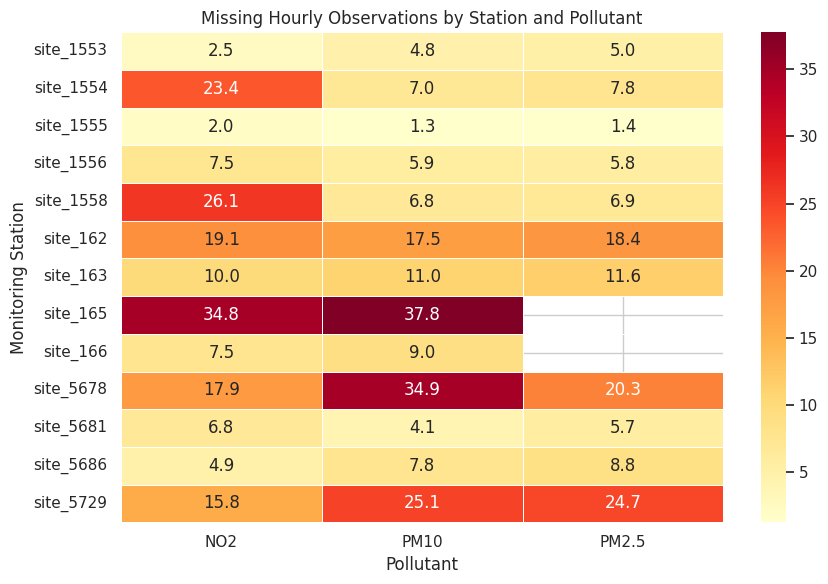

In [19]:
gap_pivot = gap_summary.pivot(
    index="station_id",
    columns="parameter_name",
    values="gap_percentage"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    gap_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Missing Hourly Observations by Station and Pollutant")
plt.xlabel("Pollutant")
plt.ylabel("Monitoring Station")
plt.tight_layout()
plt.show()

In [20]:
# Count invalid readings before cleaning
invalid_count = (aq_clean["value"] == 999.99).sum()

# Replace sentinel values with NaN
aq_clean.loc[aq_clean["value"] == 999.99, "value"] = np.nan

print("Invalid readings identified:", invalid_count)
print("Invalid readings converted to NaN:",
      aq_clean["value"].isna().sum())

Invalid readings identified: 17
Invalid readings converted to NaN: 17


In [21]:
expected_hours = pd.date_range(
    "2024-01-01 00:00:00",
    "2024-12-31 23:00:00",
    freq="h"
)

hourly_groups = []

for (station, pollutant), group in aq_clean.groupby(
    ["station_id", "parameter_name"]
):
    series = (
        group.set_index("collected_at")["value"]
        .sort_index()
        .reindex(expected_hours)
    )

    # Interpolate internally, but do not fill leading/trailing gaps
    interpolated = series.interpolate(
        method="time",
        limit_area="inside"
    )

    missing = series.isna()

    # Identify consecutive missing-value runs
    run_id = missing.ne(missing.shift()).cumsum()
    run_length = missing.groupby(run_id).transform("sum")

    # Fill only complete gaps of 1–3 consecutive hours
    fill_mask = (
        missing
        & (run_length <= 3)
        & interpolated.notna()
    )

    cleaned_series = series.copy()
    cleaned_series.loc[fill_mask] = interpolated.loc[fill_mask]

    hourly_groups.append(
        pd.DataFrame({
            "station_id": station,
            "parameter_name": pollutant,
            "collected_at": expected_hours,
            "value": cleaned_series.values
        })
    )

aq_hourly_complete = pd.concat(
    hourly_groups, ignore_index=True
)

print("Rows after hourly reindexing:", len(aq_hourly_complete))
print("Remaining missing readings:", aq_hourly_complete["value"].isna().sum())
print("Interpolated readings:",
      aq_hourly_complete["value"].notna().sum() - aq_clean["value"].notna().sum())

Rows after hourly reindexing: 325008
Remaining missing readings: 38076
Interpolated readings: 2998


In [22]:
gap_after = (
    aq_hourly_complete.groupby(
        ["station_id", "parameter_name"]
    )
    .agg(
        expected_hours=("collected_at", "size"),
        available_readings=("value", "count"),
        remaining_gaps=("value", lambda x: x.isna().sum())
    )
    .reset_index()
)

gap_after["gap_percentage"] = (
    gap_after["remaining_gaps"]
    / gap_after["expected_hours"] * 100
).round(2)

display(gap_after.sort_values(
    "remaining_gaps", ascending=False
))

print("\nTotal remaining gaps:",
      gap_after["remaining_gaps"].sum())

,station_id,parameter_name,expected_hours,available_readings,remaining_gaps,gap_percentage
22,site_165,PM10,8784,5530,3254,37.04
21,site_165,NO2,8784,5751,3033,34.53
26,site_5678,PM10,8784,5911,2873,32.71
12,site_1558,NO2,8784,6712,2072,23.59
35,site_5729,PM10,8784,6718,2066,23.52
3,site_1554,NO2,8784,6744,2040,23.22
36,site_5729,PM2.5,8784,6764,2020,23.00
15,site_162,NO2,8784,7163,1621,18.45
27,site_5678,PM2.5,8784,7183,1601,18.23
25,site_5678,NO2,8784,7237,1547,17.61



Total remaining gaps: 38076


In [28]:
# Build every expected station-pollutant combination
all_stations = sorted(aq_clean["station_id"].dropna().unique())
all_pollutants = ["PM10", "PM2.5", "NO2"]

expected_hours = pd.date_range(
    "2024-01-01 00:00:00",
    "2024-12-31 23:00:00",
    freq="h"
)

complete_combinations = pd.MultiIndex.from_product(
    [all_stations, all_pollutants],
    names=["station_id", "parameter_name"]
)

corrected_gap_records = []

for station, pollutant in complete_combinations:
    group = aq_hourly_complete[
        (aq_hourly_complete["station_id"] == station) &
        (aq_hourly_complete["parameter_name"] == pollutant)
    ]

    observed = group["value"].count()

    corrected_gap_records.append({
        "station_id": station,
        "parameter_name": pollutant,
        "expected_hours": len(expected_hours),
        "available_readings": observed,
        "missing_hours": len(expected_hours) - observed,
        "gap_percentage": round(
            (len(expected_hours) - observed) /
            len(expected_hours) * 100, 2
        )
    })

corrected_gap_summary = pd.DataFrame(corrected_gap_records)

display(
    corrected_gap_summary.sort_values(
        "gap_percentage", ascending=False
    )
)

print("Expected combinations:", len(complete_combinations))
print("Expected total observations:",
      len(complete_combinations) * len(expected_hours))
print("Total missing observations:",
      corrected_gap_summary["missing_hours"].sum())

,station_id,parameter_name,expected_hours,available_readings,missing_hours,gap_percentage
22,site_165,PM2.5,8784,0,8784,100.00
25,site_166,PM2.5,8784,0,8784,100.00
21,site_165,PM10,8784,5530,3254,37.04
23,site_165,NO2,8784,5751,3033,34.53
27,site_5678,PM10,8784,5911,2873,32.71
14,site_1558,NO2,8784,6712,2072,23.59
36,site_5729,PM10,8784,6718,2066,23.52
5,site_1554,NO2,8784,6744,2040,23.22
37,site_5729,PM2.5,8784,6764,2020,23.00
17,site_162,NO2,8784,7163,1621,18.45


Expected combinations: 39
Expected total observations: 342576
Total missing observations: 55644


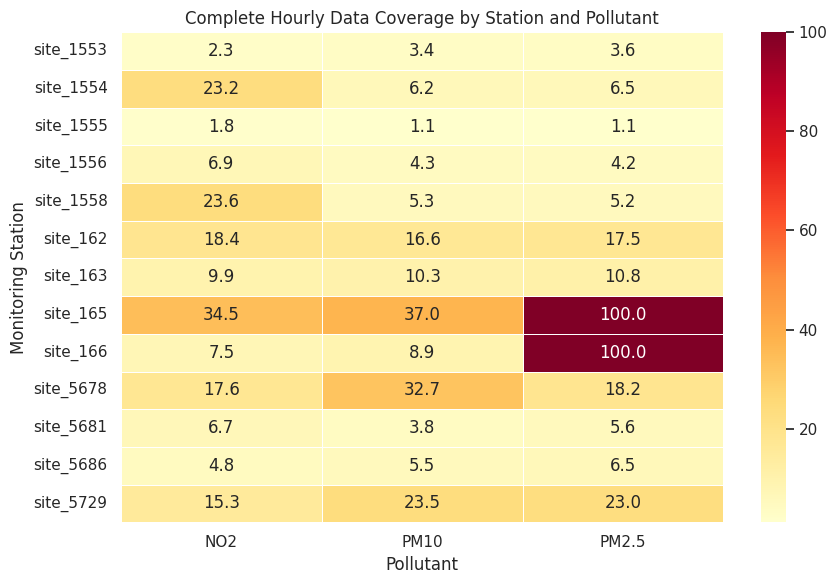

In [29]:
gap_pivot_corrected = corrected_gap_summary.pivot(
    index="station_id",
    columns="parameter_name",
    values="gap_percentage"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    gap_pivot_corrected,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Complete Hourly Data Coverage by Station and Pollutant")
plt.xlabel("Pollutant")
plt.ylabel("Monitoring Station")
plt.tight_layout()
plt.show()

In [30]:
cleaning_log_records = [
    ("Air Quality", "Timestamp conversion", "collected_at converted to datetime"),
    ("Weather", "Timestamp conversion", "timestamp converted to datetime"),
    ("BBMP 2023", "Timestamp conversion", "Grievance Date converted to datetime"),
    ("BBMP 2024", "Timestamp conversion", "Grievance Date converted to datetime"),
    ("BBMP 2023", "Missing remarks", "1616 literal \\N values converted to NaN"),
    ("BBMP 2024", "Missing remarks", "6639 literal \\N values converted to NaN"),
    ("Air Quality", "Invalid readings", "17 readings of 999.99 converted to NaN"),
    ("Air Quality", "Short gaps", "Internal gaps up to 3 hours interpolated"),
    ("Air Quality", "Long gaps", "Retained as missing"),
    ("Air Quality", "Unavailable combinations", "Two combinations retained as unavailable"),
    ("Air Quality", "Outliers", "IQR-flagged observations retained"),
    ("Weather", "Outliers", "Statistical extremes retained"),
    ("All datasets", "Duplicates", "No exact duplicate rows removed")
]

cleaning_log_df = pd.DataFrame(
    cleaning_log_records,
    columns=["Dataset", "Issue", "Action"]
)

display(cleaning_log_df)

,Dataset,Issue,Action
0,Air Quality,Timestamp conversion,collected_at converted to datetime
1,Weather,Timestamp conversion,timestamp converted to datetime
2,BBMP 2023,Timestamp conversion,Grievance Date converted to datetime
3,BBMP 2024,Timestamp conversion,Grievance Date converted to datetime
4,BBMP 2023,Missing remarks,1616 literal \N values converted to NaN
5,BBMP 2024,Missing remarks,6639 literal \N values converted to NaN
6,Air Quality,Invalid readings,17 readings of 999.99 converted to NaN
7,Air Quality,Short gaps,Internal gaps up to 3 hours interpolated
8,Air Quality,Long gaps,Retained as missing
9,Air Quality,Unavailable combinations,Two combinations retained as unavailable


Section 6 — Create daily analysis datasets

In [31]:
# Exclude unavailable readings; retain valid observed and interpolated values
aq_hourly_complete["date"] = aq_hourly_complete["collected_at"].dt.normalize()

# Step 1: Daily average for each station and pollutant
aq_station_daily = (
    aq_hourly_complete
    .groupby(["date", "station_id", "parameter_name"], as_index=False)
    .agg(
        station_daily_mean=("value", "mean"),
        valid_hours=("value", "count")
    )
)

# Step 2: City-level daily average across stations
aq_daily = (
    aq_station_daily
    .groupby(["date", "parameter_name"], as_index=False)
    .agg(
        city_mean=("station_daily_mean", "mean"),
        stations_reporting=("station_daily_mean", "count")
    )
)

# Convert pollutants into separate columns
aq_daily_wide = aq_daily.pivot(
    index="date",
    columns="parameter_name",
    values="city_mean"
).reset_index()

aq_daily_wide.columns.name = None

print("Daily air-quality summary:")
print("Rows:", len(aq_daily_wide))
display(aq_daily_wide.head())

Daily air-quality summary:
Rows: 366


,date,NO2,PM10,PM2.5
0,2024-01-01,18.09,87.85,42.17
1,2024-01-02,18.05,95.72,44.83
2,2024-01-03,18.10,96.00,43.79
3,2024-01-04,18.32,110.06,47.99
4,2024-01-05,17.61,87.13,37.33


In [32]:
weather_clean["date"] = weather_clean["timestamp"].dt.normalize()

weather_daily = (
    weather_clean
    .groupby("date", as_index=False)
    .agg(
        mean_temperature=("temperature", "mean"),
        min_temperature=("temperature", "min"),
        max_temperature=("temperature", "max"),
        mean_humidity=("humidity", "mean"),
        total_precipitation=("precipitation", "sum"),
        mean_wind_speed=("wind_speed", "mean"),
        max_wind_speed=("wind_speed", "max")
    )
)

print("Daily weather summary:")
print("Rows:", len(weather_daily))
display(weather_daily.head())

Daily weather summary:
Rows: 366


,date,mean_temperature,min_temperature,max_temperature,mean_humidity,total_precipitation,mean_wind_speed,max_wind_speed
0,2024-01-01,21.77,16.60,28.40,65.96,0.00,12.42,19.10
1,2024-01-02,21.93,18.20,27.60,66.12,0.00,14.07,18.80
2,2024-01-03,21.57,16.40,27.40,68.29,0.00,12.65,16.90
3,2024-01-04,21.38,18.20,25.50,73.75,2.70,13.81,17.70
4,2024-01-05,22.44,18.60,27.00,72.75,0.20,11.95,16.20


In [33]:
# Add date-only columns
bbmp23_clean["date"] = bbmp23_clean["Grievance Date"].dt.normalize()
bbmp24_clean["date"] = bbmp24_clean["Grievance Date"].dt.normalize()

# Main analysis uses 2024
complaints_daily = (
    bbmp24_clean
    .groupby("date")
    .agg(
        total_complaints=("Complaint ID", "count"),
        wards_reported=("Ward Name", "nunique"),
        categories_reported=("Category", "nunique")
    )
    .reset_index()
)

# Daily complaint counts by category
complaints_category_daily = (
    bbmp24_clean
    .groupby(["date", "Category"])
    .size()
    .reset_index(name="complaint_count")
)

print("Daily complaint summary:")
print("Days with complaint records:", len(complaints_daily))
display(complaints_daily.head())

print("\nMost frequent complaint categories:")
display(
    bbmp24_clean["Category"]
    .value_counts()
    .head(10)
    .rename_axis("Category")
    .reset_index(name="Complaints")
)

Daily complaint summary:
Days with complaint records: 362


,date,total_complaints,wards_reported,categories_reported
0,2024-01-01,273,116,14
1,2024-01-02,360,129,14
2,2024-01-03,401,136,15
3,2024-01-04,379,127,15
4,2024-01-05,383,132,15



Most frequent complaint categories:


,Category,Complaints
0,Electrical,75155
1,Solid Waste (Garbage) Related,57329
2,Road Maintenance(Engg),24973
3,Health Dept,15324
4,Forest,11723
5,Road Infrastructure,4870
6,veterinary,4771
7,Others,2809
8,Town Planning,1813
9,Storm Water Drain(SWD),1677


In [34]:
date_dimension = pd.DataFrame({
    "date": pd.date_range(
        start="2024-01-01",
        end="2024-12-31",
        freq="D"
    )
})

# Merge daily environmental and complaint summaries
daily_analysis = (
    date_dimension
    .merge(aq_daily_wide, on="date", how="left")
    .merge(weather_daily, on="date", how="left")
    .merge(complaints_daily, on="date", how="left")
)

# A date with no complaint records is treated as zero complaints
daily_analysis["total_complaints"] = (
    daily_analysis["total_complaints"].fillna(0).astype(int)
)

daily_analysis["wards_reported"] = (
    daily_analysis["wards_reported"].fillna(0).astype(int)
)

daily_analysis["categories_reported"] = (
    daily_analysis["categories_reported"].fillna(0).astype(int)
)

print("Integrated daily dataset shape:", daily_analysis.shape)
display(daily_analysis.head(10))

Integrated daily dataset shape: (366, 14)


,date,NO2,PM10,PM2.5,mean_temperature,min_temperature,max_temperature,mean_humidity,total_precipitation,mean_wind_speed,max_wind_speed,total_complaints,wards_reported,categories_reported
0,2024-01-01,18.09,87.85,42.17,21.77,16.60,28.40,65.96,0.00,12.42,19.10,273,116,14
1,2024-01-02,18.05,95.72,44.83,21.93,18.20,27.60,66.12,0.00,14.07,18.80,360,129,14
2,2024-01-03,18.10,96.00,43.79,21.57,16.40,27.40,68.29,0.00,12.65,16.90,401,136,15
3,2024-01-04,18.32,110.06,47.99,21.38,18.20,25.50,73.75,2.70,13.81,17.70,379,127,15
4,2024-01-05,17.61,87.13,37.33,22.44,18.60,27.00,72.75,0.20,11.95,16.20,383,132,15
5,2024-01-06,18.62,92.12,32.97,22.81,19.30,28.70,73.08,1.20,14.29,17.30,350,124,14
6,2024-01-07,18.20,65.31,27.43,22.08,17.00,27.80,71.04,0.00,14.18,18.10,342,112,15
7,2024-01-08,17.46,52.53,21.54,20.35,18.40,23.50,88.29,2.40,17.80,21.20,412,137,14
8,2024-01-09,17.30,72.32,81.46,21.64,18.80,26.60,76.71,1.00,18.09,25.30,412,144,18
9,2024-01-10,17.32,87.23,85.00,20.92,17.20,25.00,71.25,0.00,15.67,19.10,377,138,17


In [35]:
holiday_records = [
    ("2024-01-01", "New Year's Day", "Observance"),
    ("2024-01-15", "Makara Sankranti", "Festival"),
    ("2024-01-26", "Republic Day", "National Holiday"),
    ("2024-03-08", "Maha Shivaratri", "Festival"),
    ("2024-03-25", "Holi", "Festival"),
    ("2024-03-29", "Good Friday", "Public Holiday"),
    ("2024-04-09", "Ugadi", "Karnataka Festival"),
    ("2024-04-11", "Eid al-Fitr", "Festival"),
    ("2024-04-14", "Ambedkar Jayanti", "Observance"),
    ("2024-04-17", "Rama Navami", "Festival"),
    ("2024-05-01", "May Day", "Public Holiday"),
    ("2024-05-10", "Basava Jayanti", "Karnataka Festival"),
    ("2024-06-17", "Bakrid", "Festival"),
    ("2024-07-17", "Muharram", "Festival"),
    ("2024-08-15", "Independence Day", "National Holiday"),
    ("2024-08-26", "Krishna Janmashtami", "Festival"),
    ("2024-09-07", "Ganesh Chaturthi", "Festival"),
    ("2024-09-16", "Eid Milad", "Festival"),
    ("2024-10-02", "Gandhi Jayanti", "National Holiday"),
    ("2024-10-11", "Ayudha Puja", "Karnataka Festival"),
    ("2024-10-12", "Vijayadashami", "Festival"),
    ("2024-10-31", "Naraka Chaturdashi / Deepavali", "Festival"),
    ("2024-11-01", "Kannada Rajyotsava", "Karnataka Public Holiday"),
    ("2024-11-02", "Bali Padyami", "Festival"),
    ("2024-12-25", "Christmas", "Public Holiday")
]

holiday_calendar = pd.DataFrame(
    holiday_records,
    columns=["date", "occasion", "occasion_type"]
)

holiday_calendar["date"] = pd.to_datetime(holiday_calendar["date"])

display(holiday_calendar)

,date,occasion,occasion_type
0,2024-01-01,New Year's Day,Observance
1,2024-01-15,Makara Sankranti,Festival
2,2024-01-26,Republic Day,National Holiday
3,2024-03-08,Maha Shivaratri,Festival
4,2024-03-25,Holi,Festival
5,2024-03-29,Good Friday,Public Holiday
6,2024-04-09,Ugadi,Karnataka Festival
7,2024-04-11,Eid al-Fitr,Festival
8,2024-04-14,Ambedkar Jayanti,Observance
9,2024-04-17,Rama Navami,Festival


In [36]:
# Calendar features
date_dimension["day_of_week"] = date_dimension["date"].dt.day_name()
date_dimension["weekday_number"] = date_dimension["date"].dt.dayofweek
date_dimension["month"] = date_dimension["date"].dt.month
date_dimension["month_name"] = date_dimension["date"].dt.month_name()
date_dimension["is_weekend"] = (
    date_dimension["weekday_number"] >= 5
)

holiday_dates = set(holiday_calendar["date"])

date_dimension["is_holiday_or_festival"] = (
    date_dimension["date"].isin(holiday_dates)
)

# Join calendar information to the integrated dataset
daily_analysis = (
    daily_analysis
    .drop(columns=[
        "day_of_week", "weekday_number", "month",
        "month_name", "is_weekend",
        "is_holiday_or_festival"
    ], errors="ignore")
    .merge(
        date_dimension,
        on="date",
        how="left"
    )
)

daily_analysis = daily_analysis.merge(
    holiday_calendar[["date", "occasion", "occasion_type"]],
    on="date",
    how="left"
)

daily_analysis["occasion"] = (
    daily_analysis["occasion"].fillna("Regular Day")
)

daily_analysis["occasion_type"] = (
    daily_analysis["occasion_type"].fillna("None")
)

print("Final integrated daily dataset:", daily_analysis.shape)
display(
    daily_analysis[
        daily_analysis["is_holiday_or_festival"]
    ][["date", "occasion", "occasion_type"]]
)

Final integrated daily dataset: (366, 22)


,date,occasion,occasion_type
0,2024-01-01,New Year's Day,Observance
14,2024-01-15,Makara Sankranti,Festival
25,2024-01-26,Republic Day,National Holiday
67,2024-03-08,Maha Shivaratri,Festival
84,2024-03-25,Holi,Festival
88,2024-03-29,Good Friday,Public Holiday
99,2024-04-09,Ugadi,Karnataka Festival
101,2024-04-11,Eid al-Fitr,Festival
104,2024-04-14,Ambedkar Jayanti,Observance
107,2024-04-17,Rama Navami,Festival


In [37]:
print("Date range:",
      daily_analysis["date"].min(),
      "to",
      daily_analysis["date"].max())

print("Number of calendar days:", len(daily_analysis))
print("Duplicate dates:", daily_analysis["date"].duplicated().sum())

print("\nMissing values after integration:")
display(
    daily_analysis.isna().sum()
    .to_frame("Missing Count")
    .sort_values("Missing Count", ascending=False)
)

print("\nIntegrated dataset preview:")
display(daily_analysis.head())

Date range: 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Number of calendar days: 366
Duplicate dates: 0

Missing values after integration:


,Missing Count
date,0
NO2,0
PM10,0
PM2.5,0
mean_temperature,0
min_temperature,0
max_temperature,0
mean_humidity,0
total_precipitation,0
mean_wind_speed,0



Integrated dataset preview:


,date,NO2,PM10,PM2.5,mean_temperature,min_temperature,max_temperature,mean_humidity,total_precipitation,mean_wind_speed,max_wind_speed,total_complaints,wards_reported,categories_reported,day_of_week,weekday_number,month,month_name,is_weekend,is_holiday_or_festival,occasion,occasion_type
0,2024-01-01,18.09,87.85,42.17,21.77,16.60,28.40,65.96,0.00,12.42,19.10,273,116,14,Monday,0,1,January,False,True,New Year's Day,Observance
1,2024-01-02,18.05,95.72,44.83,21.93,18.20,27.60,66.12,0.00,14.07,18.80,360,129,14,Tuesday,1,1,January,False,False,Regular Day,None
2,2024-01-03,18.10,96.00,43.79,21.57,16.40,27.40,68.29,0.00,12.65,16.90,401,136,15,Wednesday,2,1,January,False,False,Regular Day,None
3,2024-01-04,18.32,110.06,47.99,21.38,18.20,25.50,73.75,2.70,13.81,17.70,379,127,15,Thursday,3,1,January,False,False,Regular Day,None
4,2024-01-05,17.61,87.13,37.33,22.44,18.60,27.00,72.75,0.20,11.95,16.20,383,132,15,Friday,4,1,January,False,False,Regular Day,None


In [38]:
print("Daily complaint statistics:")
display(daily_analysis["total_complaints"].describe())

print("\nEnvironmental coverage:")
print("Days with PM10 data:",
      daily_analysis["PM10"].notna().sum())
print("Days with PM2.5 data:",
      daily_analysis["PM2.5"].notna().sum())
print("Days with NO2 data:",
      daily_analysis["NO2"].notna().sum())
print("Days with weather data:",
      daily_analysis["mean_temperature"].notna().sum())

print("\nCorrelation between daily variables:")
display(
    daily_analysis[
        [
            "PM10", "PM2.5", "NO2",
            "mean_temperature", "total_precipitation",
            "mean_humidity", "total_complaints"
        ]
    ].corr(numeric_only=True).round(3)
)

Daily complaint statistics:


,total_complaints
count,366.00
mean,565.62
std,214.30
min,0.00
25%,404.50
50%,549.00
75%,697.00
max,"1,518.00"



Environmental coverage:
Days with PM10 data: 366
Days with PM2.5 data: 366
Days with NO2 data: 366
Days with weather data: 366

Correlation between daily variables:


,PM10,PM2.5,NO2,mean_temperature,total_precipitation,mean_humidity,total_complaints
PM10,1.00,0.92,0.33,0.23,-0.45,-0.60,-0.36
PM2.5,0.92,1.00,0.34,0.23,-0.41,-0.59,-0.37
NO2,0.33,0.34,1.00,-0.34,-0.07,0.00,0.06
mean_temperature,0.23,0.23,-0.34,1.00,-0.24,-0.78,-0.35
total_precipitation,-0.45,-0.41,-0.07,-0.24,1.00,0.51,0.33
mean_humidity,-0.60,-0.59,0.00,-0.78,0.51,1.00,0.54
total_complaints,-0.36,-0.37,0.06,-0.35,0.33,0.54,1.00


In [39]:
# Identify dates present in the original 2024 complaint dataset
complaint_dates = set(complaints_daily["date"])

daily_analysis["complaint_data_present"] = (
    daily_analysis["date"].isin(complaint_dates)
)

# Preserve unknown complaint counts as missing instead of assuming zero
daily_analysis.loc[
    ~daily_analysis["complaint_data_present"],
    "total_complaints"
] = np.nan

dates_without_complaints = daily_analysis.loc[
    ~daily_analysis["complaint_data_present"],
    ["date", "day_of_week", "occasion"]
]

print("Dates without BBMP complaint records:",
      len(dates_without_complaints))

display(dates_without_complaints)

print("\nComplaint count summary after correction:")
display(daily_analysis["total_complaints"].describe())

Dates without BBMP complaint records: 4


,date,day_of_week,occasion
242,2024-08-30,Friday,Regular Day
243,2024-08-31,Saturday,Regular Day
244,2024-09-01,Sunday,Regular Day
245,2024-09-02,Monday,Regular Day



Complaint count summary after correction:


,total_complaints
count,362.00
mean,571.87
std,207.00
min,215.00
25%,409.75
50%,555.50
75%,697.00
max,"1,518.00"


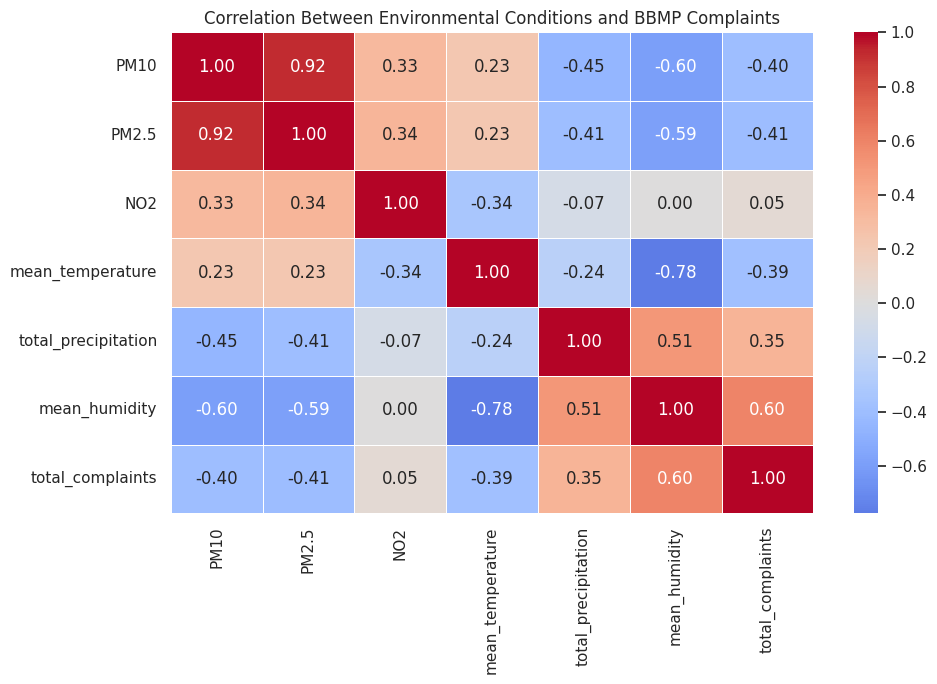

In [40]:
correlation_columns = [
    "PM10",
    "PM2.5",
    "NO2",
    "mean_temperature",
    "total_precipitation",
    "mean_humidity",
    "total_complaints"
]

correlation_data = daily_analysis[correlation_columns]

correlation_matrix = correlation_data.corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Environmental Conditions and BBMP Complaints")
plt.tight_layout()
plt.show()

In [41]:
hourly_aq_pivot_source = aq_hourly_complete.copy()

hourly_aq_pivot_source["hour"] = (
    hourly_aq_pivot_source["collected_at"].dt.hour
)

hourly_aq_pivot_source["weekday"] = (
    hourly_aq_pivot_source["collected_at"].dt.day_name()
)

# Average PM2.5 across available stations for each timestamp
pm25_hourly_city = (
    hourly_aq_pivot_source[
        hourly_aq_pivot_source["parameter_name"] == "PM2.5"
    ]
    .groupby(["collected_at", "hour", "weekday"], as_index=False)
    .agg(city_pm25=("value", "mean"))
)

print("Hourly city-level PM2.5 records:",
      len(pm25_hourly_city))

display(pm25_hourly_city.head())

Hourly city-level PM2.5 records: 8784


,collected_at,hour,weekday,city_pm25
0,2024-01-01 00:00:00,0,Monday,37.90
1,2024-01-01 01:00:00,1,Monday,46.54
2,2024-01-01 02:00:00,2,Monday,43.62
3,2024-01-01 03:00:00,3,Monday,40.39
4,2024-01-01 04:00:00,4,Monday,41.36


In [42]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

pandas_pivot = pm25_hourly_city.pivot_table(
    index="hour",
    columns="weekday",
    values="city_pm25",
    aggfunc="mean"
)

pandas_pivot = pandas_pivot.reindex(
    columns=weekday_order
)

display(pandas_pivot.round(2))

weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
hour,,,,,,,
0,33.76,33.86,36.57,34.36,34.15,35.04,33.92
1,32.83,31.19,35.15,32.89,31.92,32.45,33.09
2,31.73,31.10,34.44,30.83,31.07,31.18,32.93
3,30.59,30.57,33.60,29.53,31.34,30.44,32.25
4,30.51,30.29,33.22,29.40,29.84,30.47,30.76
5,30.41,31.11,34.06,29.95,29.41,31.04,30.66
6,31.97,32.35,35.77,30.19,30.78,33.09,32.14
7,33.38,35.37,37.29,31.66,32.05,37.46,33.23
8,33.84,36.50,37.17,32.39,32.62,35.33,33.13


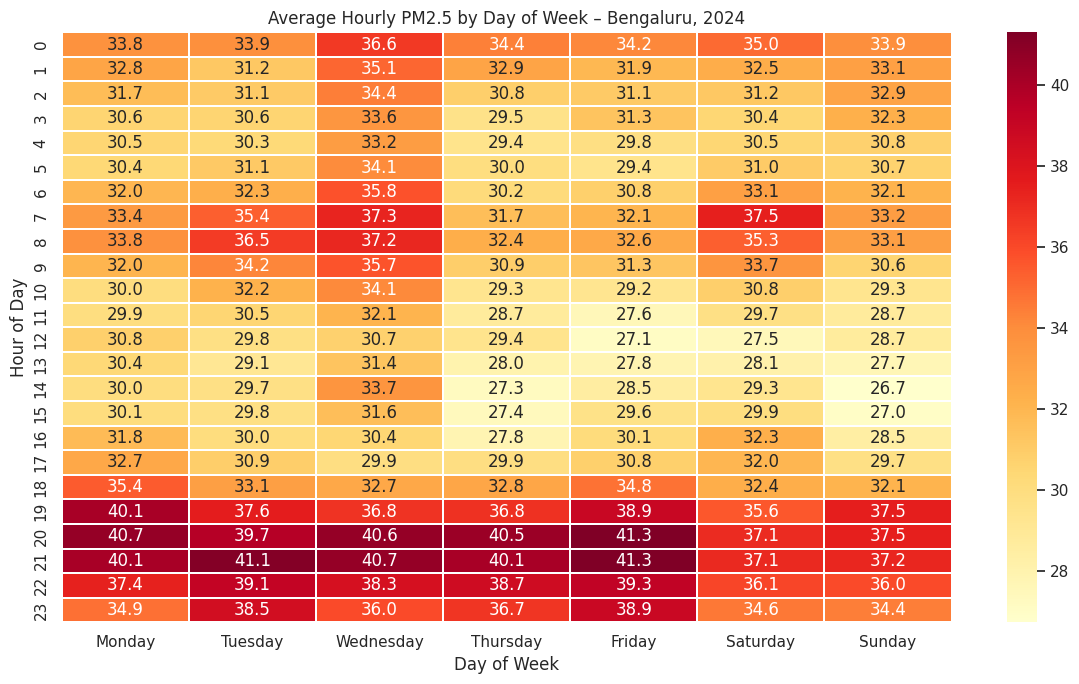

In [43]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    pandas_pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.3
)

plt.title("Average Hourly PM2.5 by Day of Week – Bengaluru, 2024")
plt.xlabel("Day of Week")
plt.ylabel("Hour of Day")
plt.tight_layout()
plt.show()

In [45]:
pivot_export = pandas_pivot.reset_index()

pivot_export.to_csv(
    "hour_weekday_pm25_pandas.csv",
    index=False
)

print("Exported: hour_weekday_pm25_pandas.csv")

Exported: hour_weekday_pm25_pandas.csv


In [46]:
from google.colab import files
import os

# Export the Pandas pivot
export_filename = "hour_weekday_pm25_pandas.csv"

pandas_pivot.to_csv(
    export_filename,
    index=True,
    index_label="hour"
)

# Verify that the file was created
if os.path.exists(export_filename):
    print("CSV created successfully:", export_filename)

    # Download to your computer
    files.download(export_filename)
else:
    print("CSV export failed.")

CSV created successfully: hour_weekday_pm25_pandas.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
!pip -q install pyspark

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType,
    TimestampType, DoubleType
)

spark = (
    SparkSession.builder
    .appName("BengaluruUrbanStressAnalysis")
    .master("local[*]")
    .config("spark.sql.session.timeZone", "Asia/Kolkata")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 4.0.5


In [48]:
# Explicit schema for hourly air-quality observations
aq_schema = StructType([
    StructField("station_id", StringType(), True),
    StructField("parameter_name", StringType(), True),
    StructField("collected_at", TimestampType(), True),
    StructField("value", DoubleType(), True)
])

# Convert Pandas rows into Spark-compatible records
aq_records = [
    (
        str(row.station_id),
        str(row.parameter_name),
        row.collected_at.to_pydatetime(),
        None if pd.isna(row.value) else float(row.value)
    )
    for row in aq_hourly_complete.itertuples(index=False)
]

aq_spark = spark.createDataFrame(aq_records, schema=aq_schema)

print("Air-quality rows in Spark:", aq_spark.count())
aq_spark.printSchema()

Air-quality rows in Spark: 325008
root
 |-- station_id: string (nullable = true)
 |-- parameter_name: string (nullable = true)
 |-- collected_at: timestamp (nullable = true)
 |-- value: double (nullable = true)



In [49]:
weather_schema = StructType([
    StructField("timestamp", TimestampType(), True),
    StructField("temperature", DoubleType(), True),
    StructField("humidity", DoubleType(), True),
    StructField("precipitation", DoubleType(), True),
    StructField("wind_speed", DoubleType(), True),
    StructField("wind_direction", DoubleType(), True)
])

weather_records = [
    (
        row.timestamp.to_pydatetime(),
        float(row.temperature),
        float(row.humidity),
        float(row.precipitation),
        float(row.wind_speed),
        float(row.wind_direction)
    )
    for row in weather_clean.itertuples(index=False)
]

weather_spark = spark.createDataFrame(
    weather_records,
    schema=weather_schema
)

print("Weather rows in Spark:", weather_spark.count())
weather_spark.printSchema()

Weather rows in Spark: 8784
root
 |-- timestamp: timestamp (nullable = true)
 |-- temperature: double (nullable = true)
 |-- humidity: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- wind_speed: double (nullable = true)
 |-- wind_direction: double (nullable = true)



In [50]:
raw_air_quality_count = len(air_quality)
hourly_grid_count = aq_spark.count()
weather_count = weather_spark.count()

print("AIR QUALITY")
print("Original observations:", raw_air_quality_count)
print("Rows after complete hourly grid:", hourly_grid_count)

print("\nWEATHER")
print("Hourly weather observations:", weather_count)

AIR QUALITY
Original observations: 283951
Rows after complete hourly grid: 325008

WEATHER
Hourly weather observations: 8784


In [51]:
aq_city_hourly_spark = (
    aq_spark
    .groupBy("collected_at", "parameter_name")
    .agg(
        F.avg("value").alias("city_mean"),
        F.count("value").alias("stations_reporting")
    )
)

print("City-level hourly air-quality rows:",
      aq_city_hourly_spark.count())

aq_city_hourly_spark.orderBy(
    "collected_at", "parameter_name"
).show(10, truncate=False)

City-level hourly air-quality rows: 26352
+-------------------+--------------+------------------+------------------+
|collected_at       |parameter_name|city_mean         |stations_reporting|
+-------------------+--------------+------------------+------------------+
|2024-01-01 05:30:00|NO2           |18.673076923076923|13                |
|2024-01-01 05:30:00|PM10          |83.73615384615385 |13                |
|2024-01-01 05:30:00|PM2.5         |37.900909090909096|11                |
|2024-01-01 06:30:00|NO2           |18.56692307692308 |13                |
|2024-01-01 06:30:00|PM10          |88.74384615384616 |13                |
|2024-01-01 06:30:00|PM2.5         |46.54363636363637 |11                |
|2024-01-01 07:30:00|NO2           |18.084615384615383|13                |
|2024-01-01 07:30:00|PM10          |89.61076923076924 |13                |
|2024-01-01 07:30:00|PM2.5         |43.622727272727275|11                |
|2024-01-01 08:30:00|NO2           |17.955384615384617|13 

In [52]:
aq_weather_spark = (
    aq_city_hourly_spark
    .join(
        weather_spark,
        aq_city_hourly_spark["collected_at"] == weather_spark["timestamp"],
        how="inner"
    )
    .drop("timestamp")
)

print("Rows after joining air quality and weather:",
      aq_weather_spark.count())

aq_weather_spark.printSchema()
aq_weather_spark.show(10, truncate=False)

Rows after joining air quality and weather: 26352
root
 |-- collected_at: timestamp (nullable = true)
 |-- parameter_name: string (nullable = true)
 |-- city_mean: double (nullable = true)
 |-- stations_reporting: long (nullable = false)
 |-- temperature: double (nullable = true)
 |-- humidity: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- wind_speed: double (nullable = true)
 |-- wind_direction: double (nullable = true)

+-------------------+--------------+------------------+------------------+-----------+--------+-------------+----------+--------------+
|collected_at       |parameter_name|city_mean         |stations_reporting|temperature|humidity|precipitation|wind_speed|wind_direction|
+-------------------+--------------+------------------+------------------+-----------+--------+-------------+----------+--------------+
|2024-01-24 11:30:00|NO2           |19.429999999999996|12                |18.0       |99.0    |0.0          |8.7       |138.0         |
|

In [53]:
aq_weather_features = (
    aq_weather_spark
    .withColumn("hour", F.hour("collected_at"))
    .withColumn("weekday_number", F.dayofweek("collected_at"))
    .withColumn(
        "weekday",
        F.date_format("collected_at", "EEEE")
    )
)

spark_hour_weekday = (
    aq_weather_features
    .groupBy("hour", "weekday_number", "weekday", "parameter_name")
    .agg(
        F.avg("city_mean").alias("average_pollutant"),
        F.avg("temperature").alias("average_temperature"),
        F.avg("humidity").alias("average_humidity"),
        F.avg("precipitation").alias("average_precipitation"),
        F.avg("wind_speed").alias("average_wind_speed"),
        F.count("city_mean").alias("valid_hourly_records")
    )
    .orderBy("weekday_number", "hour", "parameter_name")
)

print("Final aggregated Spark rows:", spark_hour_weekday.count())
spark_hour_weekday.show(15, truncate=False)

Final aggregated Spark rows: 504
+----+--------------+-------+--------------+------------------+-------------------+-----------------+---------------------+------------------+--------------------+
|hour|weekday_number|weekday|parameter_name|average_pollutant |average_temperature|average_humidity |average_precipitation|average_wind_speed|valid_hourly_records|
+----+--------------+-------+--------------+------------------+-------------------+-----------------+---------------------+------------------+--------------------+
|0   |1             |Sunday |NO2           |18.636638497720227|24.386538461538464 |64.57692307692308|0.03461538461538461  |11.342307692307694|52                  |
|0   |1             |Sunday |PM10          |84.19617498206921 |24.386538461538464 |64.57692307692308|0.03461538461538462  |11.342307692307694|52                  |
|0   |1             |Sunday |PM2.5         |35.6101926961927  |24.38653846153845  |64.57692307692308|0.03461538461538461  |11.342307692307692|52   

In [54]:
processing_counts = [
    ("Original air-quality observations", raw_air_quality_count),
    ("Complete station-pollutant hourly grid", hourly_grid_count),
    ("City-level hourly air-quality records", aq_city_hourly_spark.count()),
    ("Records after weather join", aq_weather_spark.count()),
    ("Final hour-weekday-pollutant aggregates", spark_hour_weekday.count())
]

spark_processing_log = pd.DataFrame(
    processing_counts,
    columns=["Processing Stage", "Row Count"]
)

display(spark_processing_log)

,Processing Stage,Row Count
0,Original air-quality observations,283951
1,Complete station-pollutant hourly grid,325008
2,City-level hourly air-quality records,26352
3,Records after weather join,26352
4,Final hour-weekday-pollutant aggregates,504


In [55]:
# Export the final Spark aggregation as CSV
spark_hour_weekday_pd = spark_hour_weekday.toPandas()

spark_hour_weekday_pd.to_csv(
    "pyspark_hour_weekday_weather_summary.csv",
    index=False
)

spark_processing_log.to_csv(
    "pyspark_processing_log.csv",
    index=False
)

print("PySpark outputs exported successfully.")

PySpark outputs exported successfully.


In [56]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.


In [57]:
expected_variables = [
    "air_quality",
    "aq",
    "weather",
    "weather_clean",
    "bbmp_2024",
    "complaints_2024",
    "stations",
    "stations_df",
    "holiday_calendar"
]

for variable in expected_variables:
    if variable in globals():
        obj = globals()[variable]
        print(
            f"{variable}: {type(obj).__name__}",
            getattr(obj, "shape", "")
        )

air_quality: DataFrame (283951, 5)
weather: DataFrame (8784, 6)
weather_clean: DataFrame (8784, 7)
complaints_2024: DataFrame (207016, 8)
stations: dict 
holiday_calendar: DataFrame (25, 3)


In [59]:
# Start with the complete 2024 date dimension
calendar_db = date_dimension.copy()

# Ensure consistent date format
calendar_db["date"] = pd.to_datetime(calendar_db["date"]).dt.normalize()
holiday_calendar["date"] = pd.to_datetime(
    holiday_calendar["date"]
).dt.normalize()

# Merge festival and holiday information
calendar_db = calendar_db.merge(
    holiday_calendar[["date", "occasion", "occasion_type"]],
    on="date",
    how="left"
)

# Rename columns for the MySQL schema
calendar_db = calendar_db.rename(columns={
    "date": "date_id",
    "day_of_week": "weekday",
    "is_holiday_or_festival": "is_holiday"
})

calendar_db["occasion"] = calendar_db["occasion"].fillna("Regular Day")

calendar_db["date_id"] = calendar_db["date_id"].dt.date

# Select required database columns
calendar_db = calendar_db[
    [
        "date_id",
        "weekday",
        "month",
        "is_weekend",
        "is_holiday",
        "occasion"
    ]
].copy()

print("Calendar table created:", calendar_db.shape)
display(calendar_db.head())

Calendar table created: (366, 6)


,date_id,weekday,month,is_weekend,is_holiday,occasion
0,2024-01-01,Monday,1,False,True,New Year's Day
1,2024-01-02,Tuesday,1,False,False,Regular Day
2,2024-01-03,Wednesday,1,False,False,Regular Day
3,2024-01-04,Thursday,1,False,False,Regular Day
4,2024-01-05,Friday,1,False,False,Regular Day


In [60]:
import os

# Create export directory
os.makedirs("mysql_export", exist_ok=True)

# Tables prepared in the previous cells
tables = {
    "stations": stations_db,
    "pollutants": pollutants_db,
    "calendar": calendar_db,
    "air_quality": aq_db,
    "weather": weather_db,
    "complaints": complaints_db
}

# Export each table
for table_name, df in tables.items():
    output_path = f"mysql_export/{table_name}.csv"
    df.to_csv(output_path, index=False)
    print(f"{table_name}: {df.shape} -> {output_path}")

print("\nAll six tables exported successfully.")

stations: (14, 4) -> mysql_export/stations.csv
pollutants: (3, 3) -> mysql_export/pollutants.csv
calendar: (366, 6) -> mysql_export/calendar.csv
air_quality: (283951, 4) -> mysql_export/air_quality.csv
weather: (8784, 7) -> mysql_export/weather.csv
complaints: (207016, 6) -> mysql_export/complaints.csv

All six tables exported successfully.


In [62]:
for table_name, df in tables.items():
    print(f"\n{'='*50}")
    print(f"TABLE: {table_name}")
    print(f"{'='*50}")
    print(df.dtypes)
    print("\nColumns:", df.columns.tolist())


TABLE: stations
station_id       object
station_name     object
latitude        float64
longitude       float64
dtype: object

Columns: ['station_id', 'station_name', 'latitude', 'longitude']

TABLE: pollutants
pollutant_id       int64
pollutant_name    object
unit              object
dtype: object

Columns: ['pollutant_id', 'pollutant_name', 'unit']

TABLE: calendar
date_id       object
weekday       object
month          int32
is_weekend      bool
is_holiday      bool
occasion      object
dtype: object

Columns: ['date_id', 'weekday', 'month', 'is_weekend', 'is_holiday', 'occasion']

TABLE: air_quality
station_id              object
pollutant_id             int64
collected_at    datetime64[ns]
value                  float64
dtype: object

Columns: ['station_id', 'pollutant_id', 'collected_at', 'value']

TABLE: weather
timestamp         datetime64[ns]
date_id                   object
temperature              float64
humidity                   int64
precipitation            float64
wi

In [63]:
sql_schema = """
CREATE DATABASE IF NOT EXISTS bengaluru_urban_analysis;
USE bengaluru_urban_analysis;

-- 1. Stations
CREATE TABLE stations (
    station_id VARCHAR(30) PRIMARY KEY,
    station_name VARCHAR(150),
    latitude DECIMAL(10,6),
    longitude DECIMAL(10,6)
);

-- 2. Pollutants
CREATE TABLE pollutants (
    pollutant_id INT PRIMARY KEY,
    pollutant_name VARCHAR(30) UNIQUE,
    unit VARCHAR(30)
);

-- 3. Calendar
CREATE TABLE calendar (
    date_id DATE PRIMARY KEY,
    weekday VARCHAR(15),
    month INT,
    is_weekend BOOLEAN,
    is_holiday BOOLEAN,
    occasion VARCHAR(100)
);

-- 4. Air Quality
CREATE TABLE air_quality (
    station_id VARCHAR(30),
    pollutant_id INT,
    collected_at DATETIME,
    value FLOAT,
    PRIMARY KEY (station_id, pollutant_id, collected_at),
    FOREIGN KEY (station_id) REFERENCES stations(station_id),
    FOREIGN KEY (pollutant_id) REFERENCES pollutants(pollutant_id)
);

-- 5. Weather
CREATE TABLE weather (
    timestamp DATETIME PRIMARY KEY,
    date_id DATE,
    temperature FLOAT,
    humidity FLOAT,
    precipitation FLOAT,
    wind_speed FLOAT,
    wind_direction INT,
    FOREIGN KEY (date_id) REFERENCES calendar(date_id)
);

-- 6. Complaints
CREATE TABLE complaints (
    complaint_id BIGINT PRIMARY KEY,
    grievance_date DATE,
    category VARCHAR(100),
    sub_category VARCHAR(150),
    ward_name VARCHAR(100),
    grievance_status VARCHAR(50),
    FOREIGN KEY (grievance_date) REFERENCES calendar(date_id)
);
"""

with open("mysql_export/schema.sql", "w") as f:
    f.write(sql_schema)

print("MySQL schema generated successfully.")

MySQL schema generated successfully.


In [64]:
from google.colab import files
files.download("mysql_export/schema.sql")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [65]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(":memory:")

# Enable foreign key constraints
conn.execute("PRAGMA foreign_keys = ON")

# Import all six tables
for name, df in tables.items():
    temp = df.copy()

    if name == "air_quality":
        temp["collected_at"] = pd.to_datetime(
            temp["collected_at"]
        ).astype(str)

    elif name == "weather":
        temp["timestamp"] = pd.to_datetime(
            temp["timestamp"]
        ).astype(str)

    elif name == "calendar":
        temp["date_id"] = temp["date_id"].astype(str)

    elif name == "complaints":
        temp["grievance_date"] = pd.to_datetime(
            temp["grievance_date"]
        ).dt.strftime("%Y-%m-%d")

    temp.to_sql(name, conn, if_exists="replace", index=False)

print("All six tables loaded into SQLite.")

All six tables loaded into SQLite.


In [66]:
queries = {
    "Query 1: Average air quality by pollutant": """
        SELECT p.pollutant_name, ROUND(AVG(a.value), 2) AS avg_value
        FROM air_quality a
        JOIN pollutants p ON a.pollutant_id = p.pollutant_id
        GROUP BY p.pollutant_name;
    """,

    "Query 2: Complaints by category": """
        SELECT category, COUNT(*) AS complaint_count
        FROM complaints
        GROUP BY category
        ORDER BY complaint_count DESC;
    """,

    "Query 3: Complaints by ward": """
        SELECT ward_name, COUNT(*) AS total_complaints
        FROM complaints
        GROUP BY ward_name
        ORDER BY total_complaints DESC
        LIMIT 10;
    """,

    "Query 4: Average rainfall and complaints by date": """
        SELECT c.grievance_date,
               COUNT(c.complaint_id) AS complaints,
               ROUND(w.precipitation, 2) AS rainfall
        FROM complaints c
        JOIN (
            SELECT date_id, AVG(precipitation) AS precipitation
            FROM weather
            GROUP BY date_id
        ) w ON c.grievance_date = w.date_id
        GROUP BY c.grievance_date
        ORDER BY complaints DESC
        LIMIT 10;
    """,

    "Query 5: Complaints on holidays vs regular days": """
        SELECT cal.is_holiday,
               COUNT(c.complaint_id) AS total_complaints,
               COUNT(DISTINCT c.grievance_date) AS reporting_days
        FROM calendar cal
        LEFT JOIN complaints c
        ON cal.date_id = c.grievance_date
        GROUP BY cal.is_holiday;
    """
}

for title, query in queries.items():
    print("\n", title)
    display(pd.read_sql_query(query, conn))


 Query 1: Average air quality by pollutant


,pollutant_name,avg_value
0,NO2,17.51
1,PM10,70.60
2,PM2.5,33.02



 Query 2: Complaints by category


,category,complaint_count
0,Electrical,75155
1,Solid Waste (Garbage) Related,57329
2,Road Maintenance(Engg),24973
3,Health Dept,15324
4,Forest,11723
5,Road Infrastructure,4870
6,veterinary,4771
7,Others,2809
8,Town Planning,1813
9,Storm Water Drain(SWD),1677



 Query 3: Complaints by ward


,ward_name,total_complaints
0,Jnanabharathi Ward,4987
1,Horamavu,4349
2,Jakkur,3978
3,Hemmigepura,3940
4,Rajarajeshwari Nagar,3912
5,Begur,3755
6,Thanisandra,3723
7,Bellandur,3679
8,Ullalu,3421
9,Doddanekkundi,3220



 Query 4: Average rainfall and complaints by date


,grievance_date,complaints,rainfall
0,2024-10-22,1518,1.14
1,2024-10-23,1319,0.84
2,2024-10-25,1294,0.00
3,2024-07-20,1289,0.12
4,2024-10-21,1227,0.74
5,2024-10-26,1126,0.00
6,2024-06-03,1112,0.03
7,2024-07-22,1090,0.06
8,2024-09-03,1063,0.06
9,2024-10-18,1033,0.35



 Query 5: Complaints on holidays vs regular days


,is_holiday,total_complaints,reporting_days
0,0,196448,337
1,1,10568,25


In [67]:
for table in tables:
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS rows FROM {table}", conn
    ).iloc[0, 0]
    print(f"{table}: {count:,} rows")

stations: 14 rows
pollutants: 3 rows
calendar: 366 rows
air_quality: 283,951 rows
weather: 8,784 rows
complaints: 207,016 rows


In [68]:
sql_queries = "\n\n".join(
    f"-- {title}\n{query}"
    for title, query in queries.items()
)

with open("urban_analysis_queries.sql", "w") as f:
    f.write("USE bengaluru_urban_analysis;\n\n")
    f.write(sql_queries)

from google.colab import files
files.download("urban_analysis_queries.sql")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

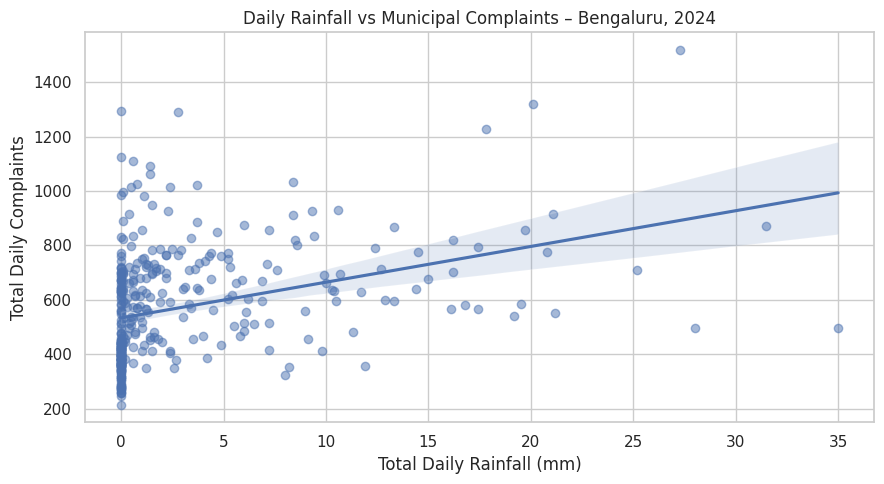

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude dates where complaint data is unavailable
plot_data = daily_analysis[
    daily_analysis["complaint_data_present"] == True
].dropna(subset=["total_precipitation", "total_complaints"])

plt.figure(figsize=(9, 5))

sns.regplot(
    data=plot_data,
    x="total_precipitation",
    y="total_complaints",
    scatter_kws={"alpha": 0.5}
)

plt.title("Daily Rainfall vs Municipal Complaints – Bengaluru, 2024")
plt.xlabel("Total Daily Rainfall (mm)")
plt.ylabel("Total Daily Complaints")
plt.tight_layout()
plt.show()

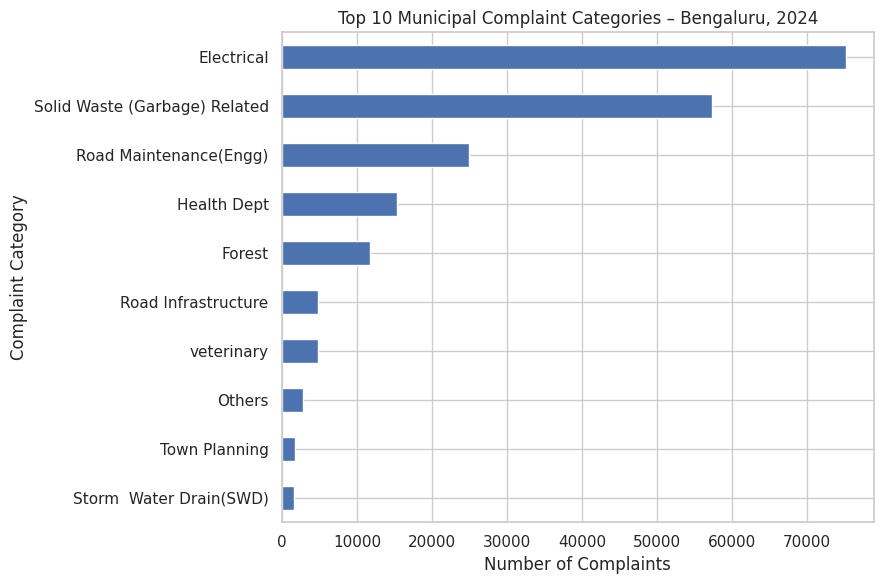

In [74]:
category_counts = (
    complaints_2024["Category"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(9, 6))
category_counts.plot(kind="barh")

plt.title("Top 10 Municipal Complaint Categories – Bengaluru, 2024")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Category")
plt.tight_layout()
plt.show()